Generando gráficas comparativas de:
   • Train: train_train_metrics.csv
   • Val:   train_validation_metrics.csv



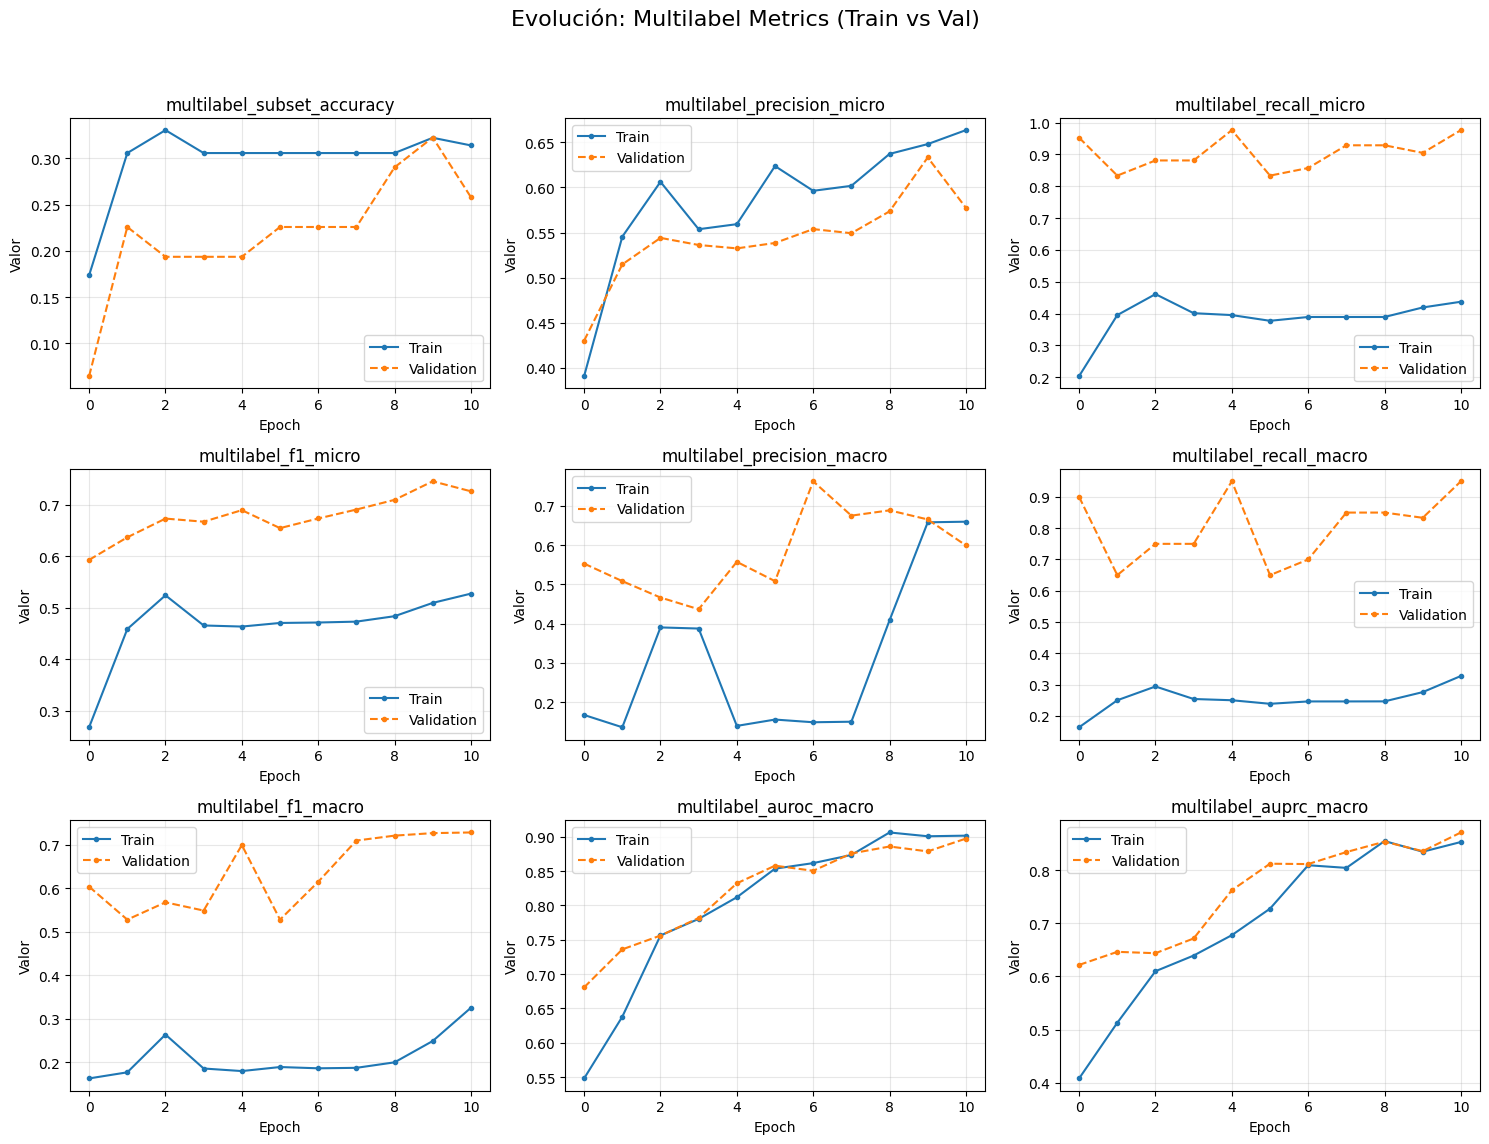

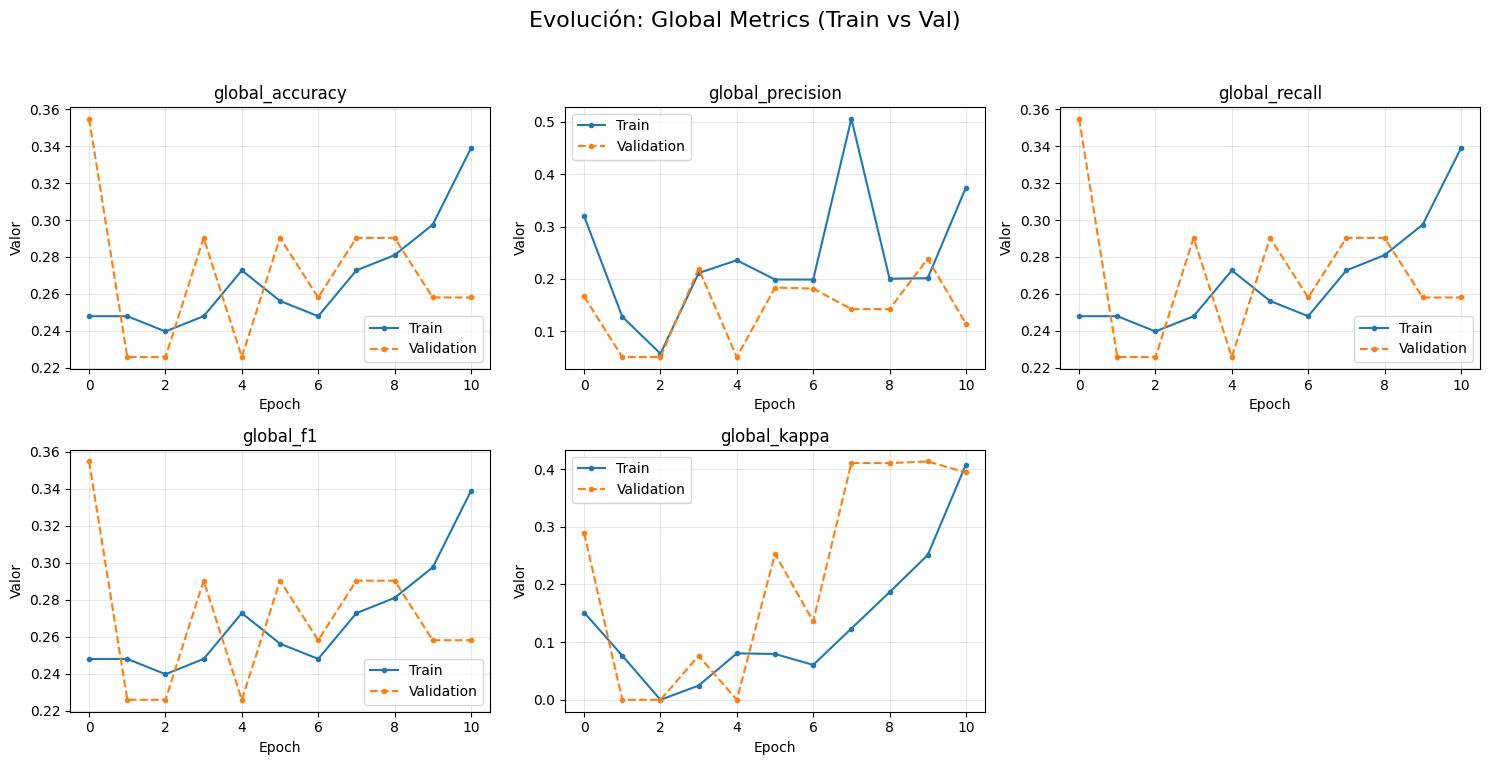

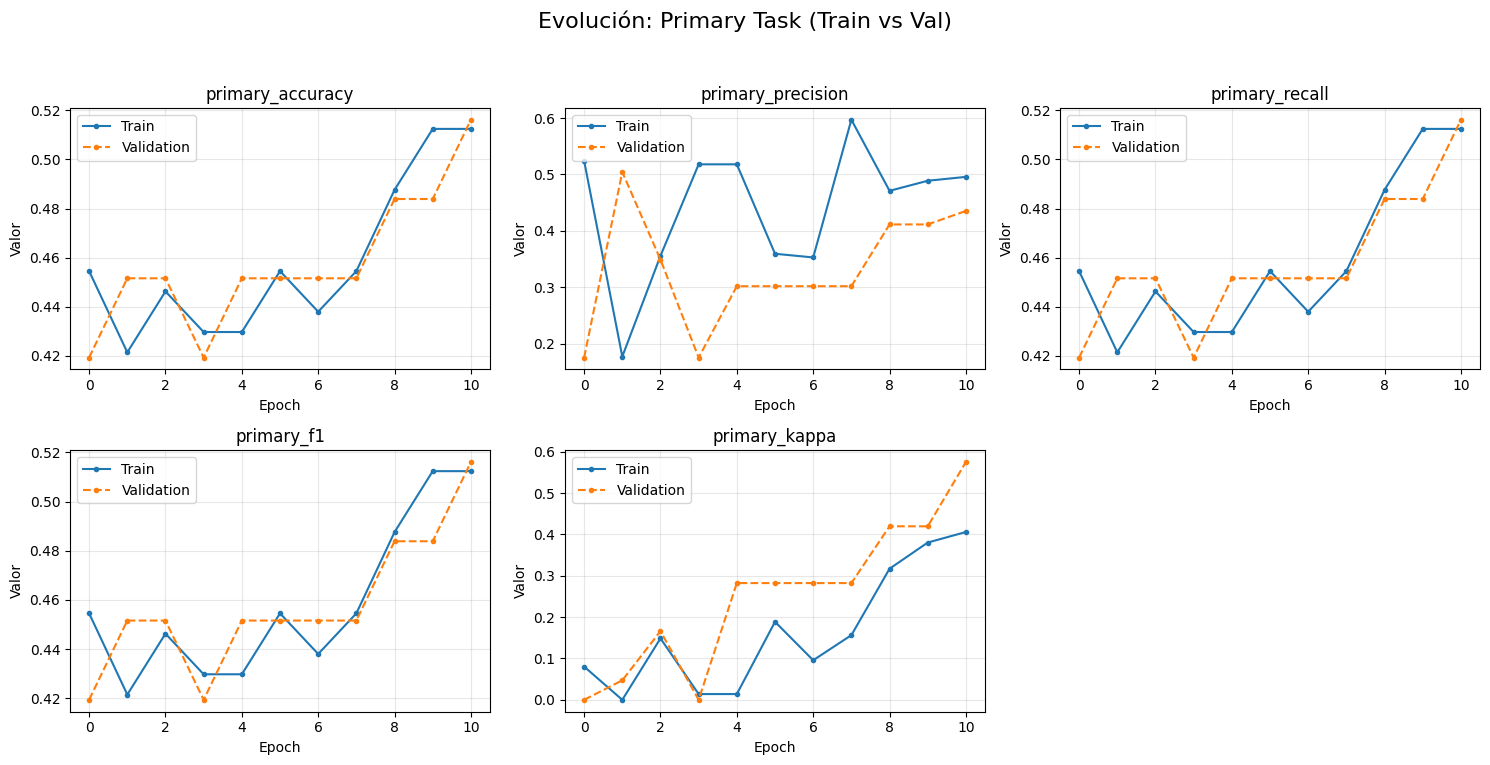

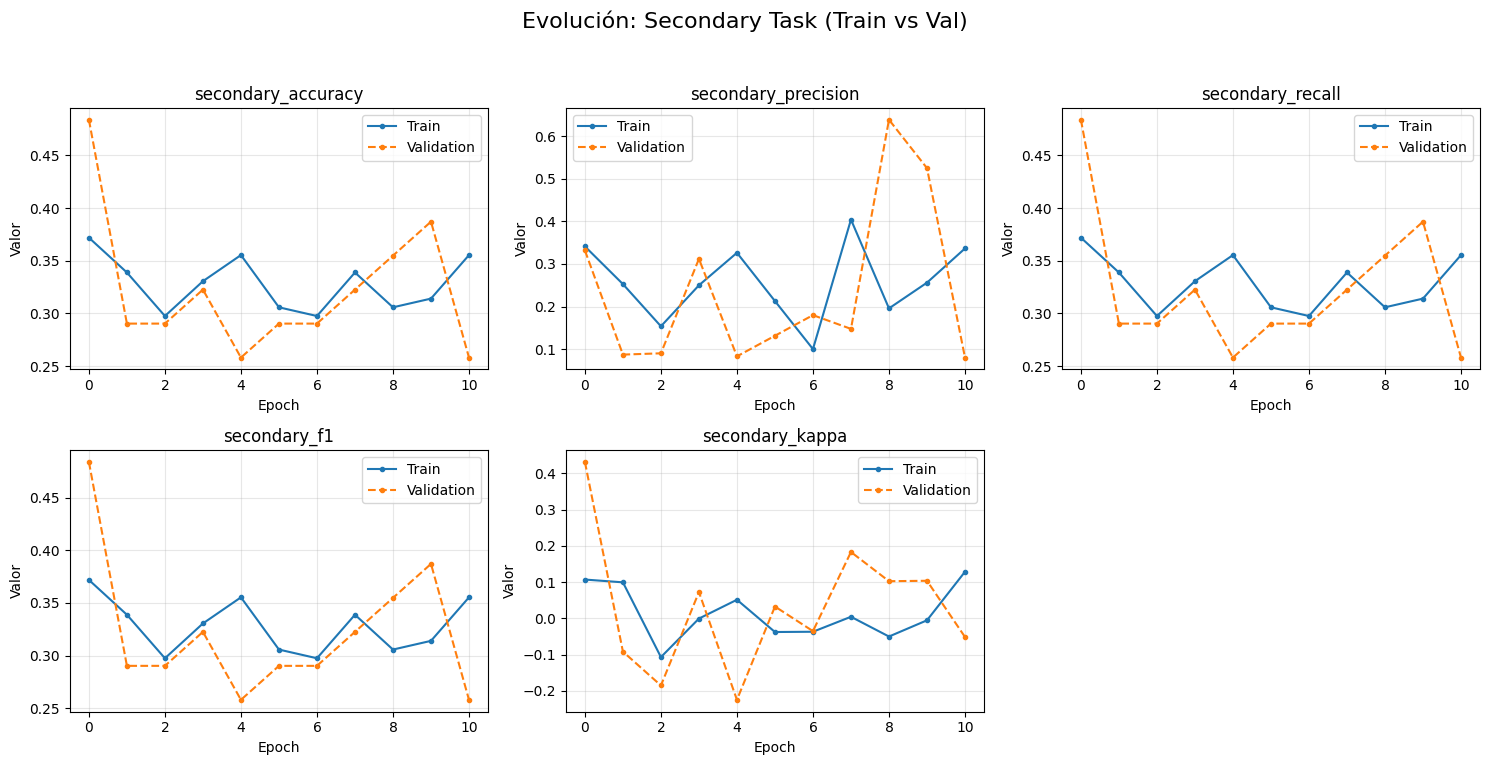


RESULTADOS FINALES EN DATASETS DE PRUEBA

 No se encontró archivo para: TEST INTERNO (Train Test)

 No se encontró archivo para: TEST EXTERNO (SICAP)


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import math

def mostrar_resultados_test(ruta_carpeta, nombre_archivo, titulo):
    if not nombre_archivo:
        print(f"\n No se encontró archivo para: {titulo}")
        return

    ruta = os.path.join(ruta_carpeta, nombre_archivo)
    
    try:
        df = pd.read_csv(ruta)
        
        # Nos quedamos con la última fila (resultados finales)
        datos = df.iloc[-1]
        
        print("\n" + "-"*60)
        print(f"  {titulo.upper()}")
        print(f"    Archivo: {nombre_archivo}")
        print("-"*60)

        # Definimos las categorías basándonos en los prefijos de las columnas
        categorias = {
            "GLOBAL METRICS": "global_",
            "PRIMARY TASK": "primary_",
            "SECONDARY TASK": "secondary_",
            "MULTILABEL METRICS": "multilabel_"
        }

        # Iteramos por cada categoría para imprimir ordenadamente
        for nombre_cat, prefijo in categorias.items():
            # Filtramos las métricas que empiezan por el prefijo actual
            metricas_grupo = [k for k in datos.index if k.startswith(prefijo)]
            
            if metricas_grupo:
                print(f"\n{nombre_cat}")
                print(f"{'Metrica':<35} | {'Valor':<10}")
                print("-" * 50)
                
                for key in metricas_grupo:
                    valor = datos[key]
                    # Limpiamos el nombre: quitamos el prefijo y ponemos mayúsculas bonitas
                    nombre_limpio = key.replace(prefijo, "").replace("_", " ").title()
                    
                    # Formateo condicional: si es float lo mostramos con 4 decimales
                    if isinstance(valor, (float, int)):
                        val_str = f"{valor:.4f}"
                    else:
                        val_str = str(valor)
                        
                    print(f"  • {nombre_limpio:<31} : {val_str}")

        print("\n" + "═"*60 + "\n")

    except Exception as e:
        print(f"Error leyendo {nombre_archivo}: {e}")

def analizar_entrenamiento_y_test(ruta_carpeta):
    if not os.path.exists(ruta_carpeta):
        print(f"La ruta '{ruta_carpeta}' no existe.")
        return

    archivos = [f for f in os.listdir(ruta_carpeta) if f.endswith('.csv')]
    
    # 1. Identificar los archivos por nombre
    f_train = next((f for f in archivos if "train_train" in f), None)
    f_val   = next((f for f in archivos if "train_validation" in f), None)
    f_test  = next((f for f in archivos if "train_test" in f), None)
    f_sicap = next((f for f in archivos if "sicap_test" in f), None)

    # --- PARTE 1: GRÁFICAS EVOLUTIVAS (Train vs Validation) ---
    if f_train and f_val:
        print(f"Generando gráficas comparativas de:")
        print(f"   • Train: {f_train}")
        print(f"   • Val:   {f_val}\n")
        
        df_t = pd.read_csv(os.path.join(ruta_carpeta, f_train)).sort_values('epoch')
        df_v = pd.read_csv(os.path.join(ruta_carpeta, f_val)).sort_values('epoch')
        
        # Definir grupos de métricas para organizar las gráficas
        grupos_metricas = {
            "Multilabel Metrics": ['multilabel_subset_accuracy', 'multilabel_precision_micro', 'multilabel_recall_micro', 
                                   'multilabel_f1_micro', 'multilabel_precision_macro', 'multilabel_recall_macro', 
                                   'multilabel_f1_macro', 'multilabel_auroc_macro', 'multilabel_auprc_macro'],
            "Global Metrics": ['global_accuracy', 'global_precision', 'global_recall', 'global_f1', 'global_kappa'],
            "Primary Task": ['primary_accuracy', 'primary_precision', 'primary_recall', 'primary_f1', 'primary_kappa'],
            "Secondary Task": ['secondary_accuracy', 'secondary_precision', 'secondary_recall', 'secondary_f1', 'secondary_kappa'],
            
        }

        for nombre_grupo, columnas in grupos_metricas.items():
            # Filtrar columnas que realmente existen en el CSV
            cols_existentes = [c for c in columnas if c in df_t.columns and c in df_v.columns]
            
            if not cols_existentes:
                continue

            # Configuración de subplots (calculamos filas necesarias)
            n_cols = 3
            n_rows = math.ceil(len(cols_existentes) / n_cols)
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
            fig.suptitle(f'Evolución: {nombre_grupo} (Train vs Val)', fontsize=16)
            axes = axes.flatten()

            for i, col in enumerate(cols_existentes):
                ax = axes[i]
                ax.plot(df_t['epoch'], df_t[col], label='Train', marker='.', linestyle='-')
                ax.plot(df_v['epoch'], df_v[col], label='Validation', marker='.', linestyle='--')
                
                ax.set_title(col)
                ax.set_xlabel('Epoch')
                ax.set_ylabel('Valor')
                ax.legend()
                ax.grid(True, alpha=0.3)

            # Ocultar subplots vacíos si los hay
            for j in range(i + 1, len(axes)):
                axes[j].axis('off')

            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            plt.show()
    else:
        print("No se encontraron los archivos 'train_train' y 'train_validation' para graficar.")

    # --- PARTE 2: RESULTADOS FINALES (Test y Sicap) ---
    print("\n" + "="*80)
    print("RESULTADOS FINALES EN DATASETS DE PRUEBA")
    print("="*80)

    mostrar_resultados_test(ruta_carpeta, f_test, "TEST INTERNO (Train Test)")
    mostrar_resultados_test(ruta_carpeta, f_sicap, "TEST EXTERNO (SICAP)")

# --- EJECUCIÓN ---
analizar_entrenamiento_y_test("/workspace/results/try_0.0001_32_100_opt_threshold")

In [2]:
import torch
def collate_fn(batch):
    """
    batch: lista de tuples (patch_id, features_tensor, label_tensor, coords)
    - patch_id: identificador del WSI
    - features_tensor: Tensor [num_patches, C, H, W] (varía por WSI)
    - label_tensor: Tensor con las etiquetas (ej. [primary, secondary])
    - coords: coordenadas de los parches
    Devuelve:
    - list_patch_id: list de patch_id (uno por WSI)
    - list_features: list de tensores (uno por WSI)
    - labels: tensor [batch_size, ...]
    - list_coords: list de tensores de coordenadas (uno por WSI)
    """
       
    patch_ids, features, labels, coords = zip(*batch)
    # features: tuple de tensores de distinta longitud -> devolvemos como lista
    list_patch_id = list(patch_ids)
    list_features = list(features)
    list_coords = list(coords)
    labels = torch.stack(labels, dim=0)

    return list_patch_id, list_features, labels, list_coords

In [ ]:
# IMPORT LIBRARIES
import os 
import sys
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from PIL import Image
import pandas as pd 
from accelerate import Accelerator

current_dir  = os.path.abspath(os.getcwd())# Directorio actual
sys.path.append(os.path.dirname(current_dir))

from utils.data_load import WSI_Dataset, create_file_label_df
from utils.utils_train import run_epoch
from utils.utils_metrics import build_heatmap, overlay_heatmap_on_image, draw_gt_patches

from models.keep_model import get_keep_ia3_model

# DEFINE PATHS 
ckpt_path = "/workspace/results/try_0.0001_32_100_opt_threshold/best_model"
result_path = "/workspace/data/patch_coord_2.xlsx"
folder_original_imgs = '/workspace/data/slides_filter'
num_img_show = 10

sicap_images_folder_path='/workspace/data/features_SICAP/patches'
sicap_labels_df_path= '/workspace/data/wsi_labels_changed_SICAP.xlsx'

# GENERAL CONFIGURATION 
print(" *Starting General Configuration ...")
CUDA_LAUNCH_BLOCKING=1
use_amp = torch.cuda.is_available()  # mixed precision if GPU available

accelerator = Accelerator()
device = accelerator.device
print(f"Usando dispositivo: {device}", flush = True)

# LOADING MODEL 
model = get_keep_ia3_model(clasification_model='graph', pretrain=False )
accelerator.load_state(ckpt_path)
model = torch.nn.SyncBatchNorm.convert_sync_batchnorm(model)
print("✓ Pesos cargados correctamente")

loss = nn.BCELoss() 
# LOADING DATA
df_test = create_file_label_df(sicap_images_folder_path, sicap_labels_df_path, NAME = 'SICAP')

label_mapping = {0: 0, 1: 0, 2: 0, 3: 1, 4: 2, 5: 3}
df_test['gleason_primary_mapped'] = df_test['gleason_primary'].map(label_mapping)
df_test['gleason_secondary_mapped'] = df_test['gleason_secondary'].map(label_mapping)
df_test['gleason_score'] = df_test['gleason_score'].astype(int)

print("Loading embeddings for Inference ...")
inference_loader = DataLoader(WSI_Dataset(df_test, df_test.index, inference_heatmap=True), shuffle=False, batch_size=4, collate_fn=collate_fn)

# INFERENCE IN MODEL
model, inference_loader = accelerator.prepare(model, inference_loader)
inference_metrics, inference_loss, test_outputs= run_epoch(model, inference_loader, device, accelerator, loss, None, mode='test',inference_heatmap=True, y_prob_threshold=0.4, tumor_abs_threshold=0.1, alpha_pe=0, alpha_pc=0)   

# METRICS 

print(f"  AUROC (Macro): {inference_metrics['multilabel']['auroc_macro']} \n")
print(f"AUROC (Weighted): {inference_metrics['multilabel']['auroc_weighted']} \n")
print(f"AUPRC (Macro): {inference_metrics['multilabel']['auprc_macro']} \n")
print(f"AUPRC (Weighted): {inference_metrics['multilabel']['auprc_weighted']} \n")

# COMAPRISON OF RESULTS
df_patch_class =  pd.read_excel(result_path)

test_outputs = test_outputs.head(num_img_show)
for index, row in test_outputs.iterrows():
    
    slide_id = row['slide_id']
    
    heatmap = build_heatmap(
        row['coords'],
        row['scores'], #row['weights']
        patch_size=512,
        scale_factor=16,
        save_path=None)
    
    # Cargar la WSI original 
    slide_id = slide_id.replace('.h5','') + '.jpg'  # Ajustar extensión si es necesario
    file_name = slide_id.split('/')[-1]
    
    wsi_path = os.path.join(folder_original_imgs,file_name)
    print(f" Cargando WSI desde: {wsi_path} ")
    print(f" Scores de la slide {row['scores']} procesada.")
    orig = Image.open(wsi_path)
    w, h = orig.size
    new_size = (w // 16, h // 16)
    orig = orig.resize(new_size, Image.BICUBIC)
    
    #Crear overlay heatmap sobre la imagen
    overlay = overlay_heatmap_on_image(orig, heatmap)

    # Dibujar parches GT en la imagen real (lado izquierdo)
    orig_with_gt = draw_gt_patches(orig.copy(), df_patch_class, file_name)

    # Crear imagen lado a lado
    w2, h2 = orig_with_gt.size
    canvas = Image.new("RGB", (w2*2, h2))
    canvas.paste(orig_with_gt, (0, 0))
    canvas.paste(overlay, (w2, 0))

    canvas.show()    

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True   n_gpus: 1
 *Starting General Configuration ...
Usando dispositivo: cuda
trainable params: 0 || all params: 414,259,969 || trainable%: 0.0
✓ Pesos cargados correctamente
Procesando WSIs: 100%|██████████| 230/230 [00:00<00:00, 1423.01it/s]
Loading embeddings for Inference ...
Loading WSI:  43%|████▎     | 98/228 [05:22<06:06,  2.82s/it]